# Cours 2 — Distances, projections, clustering (7 jeux ERP)

**M2 Data Science · Data Mining · Travail de groupe · Domaine logistique**

Sept fichiers ERP sources : partenaires, installations, bons de réception, mouvements correctifs, inventaire mensuel, **lignes de commandes d’achat**, **expéditions**. Les calculs utilisent exclusivement les données ERP ; tous les signaux sont des *hypothèses à vérifier*, jamais des preuves de fraude.

## 1. Comparer des entités de nature homogène

Le cours 2 aborde : sélection des variables, distances euclidienne / cosinus, normalisation, PCA, t-SNE et clustering. **On ne met pas dans la même matrice un fournisseur, un camion et une commande.** Nous construisons deux vues :

- **Partenaires** : nombre de commandes, réceptions, expéditions envoyées/reçues/transportées, sites exploités, diversité d'unités et volumes *en nombre de lignes* ;
- **Sites** : commandes émises, réceptions, départs et arrivées d'expédition, ajustements et inventaires.

Les **statuts métier et classes de risque** restent réservés à l'interprétation, non à l'entraînement, pour éviter une analyse tautologique.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if not (ROOT/'data/raw').exists(): ROOT=ROOT.parent
assert (ROOT/'data/raw').exists(), "Ouvrir le notebook depuis la racine du dépôt ou son répertoire notebooks/"
SEED=42
pd.set_option('display.max_columns',35)
pd.set_option('display.max_colwidth',85)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
D=ROOT/'data/part1_clean';OUT=ROOT/'data/part2_cluster';OUT.mkdir(parents=True,exist_ok=True)
def load(t):return pd.read_csv(D/f'{t}_clean.csv',dtype={"purchase_order_number":str,"receipt_number":str,"shipment_number":str})
bp=load('erp_business_partners');fc=load('erp_facilities');po=load('purchase_order_lines');rc=load('goods_receipts');sh=load('shipments');ad=load('inventory_adjustments');mo=load('inventory_month_end')


## 2. Ingénierie de variables : profils partenaires enrichis par commandes + expéditions

On compte les **événements**, sans additionner leurs quantités physiques hétérogènes. Ainsi `n_shipment_sent`, `n_shipment_received`, `n_shipment_carried` représentent des nombres de lignes d'expéditions ; `n_orders` et `n_receipts` représentent des lignes de transaction.

In [2]:
profile=bp[['partner_code','partner_name','partner_role','partner_status','risk_class','external_registration_number']].copy().set_index('partner_code')
def add_counts(frame,key,feature,where=None):
 f=frame if where is None else frame.loc[where]
 profile[feature]=profile.index.map(f.groupby(key).size()).fillna(0).astype(int)
add_counts(po,'supplier_partner_code','n_orders')
add_counts(rc,'supplier_partner_code','n_receipts')
add_counts(rc,'supplier_partner_code','n_inspection_held',rc.inspection_status.eq('held'))
add_counts(sh,'sender_partner_code','n_shipments_sent')
add_counts(sh,'receiver_partner_code','n_shipments_received')
add_counts(sh,'carrier_partner_code','n_shipments_carried')
add_counts(sh,'sender_partner_code','n_restricted_shipments',sh.authorization_class.eq('restricted'))
add_counts(fc,'operating_partner_code','n_facilities_operated')
profile['n_facilities_served']=profile.index.map(rc.groupby('supplier_partner_code').receiving_facility_code.nunique()).fillna(0)
profile['n_order_categories']=profile.index.map(po.groupby('supplier_partner_code').item_category.nunique()).fillna(0)
profile['n_shipment_categories']=profile.index.map(sh.groupby('sender_partner_code').item_category.nunique()).fillna(0)
profile=profile.reset_index()
features=[c for c in profile if c.startswith('n_')]
assert len(features)>=10
X=StandardScaler().fit_transform(np.log1p(profile[features].fillna(0)))
print('Variables utilisées :',features)
display(profile[['partner_code']+features].sort_values('n_shipments_sent',ascending=False).head(10))


Variables utilisées : ['n_orders', 'n_receipts', 'n_inspection_held', 'n_shipments_sent', 'n_shipments_received', 'n_shipments_carried', 'n_restricted_shipments', 'n_facilities_operated', 'n_facilities_served', 'n_order_categories', 'n_shipment_categories']


,partner_code,n_orders,n_receipts,n_inspection_held,n_shipments_sent,n_shipments_received,n_shipments_carried,n_restricted_shipments,n_facilities_operated,n_facilities_served,n_order_categories,n_shipment_categories
77,BP-30078,111,109,6,90,56,42,12,4,7.0,18.0,15.0
55,BP-30056,27,25,1,35,20,0,10,0,4.0,13.0,12.0
9,BP-30010,0,0,0,9,5,0,0,0,0.0,0.0,8.0
16,BP-30017,7,6,0,9,6,0,0,0,6.0,5.0,6.0
67,BP-30068,8,8,2,7,3,0,0,0,5.0,8.0,5.0
3,BP-30004,0,0,0,7,5,0,0,0,0.0,0.0,6.0
8,BP-30009,13,13,0,7,8,0,0,0,9.0,9.0,5.0
60,BP-30061,0,0,0,7,6,0,3,0,0.0,0.0,6.0
32,BP-30033,12,11,2,7,10,0,1,1,9.0,8.0,7.0
29,BP-30030,10,10,0,7,3,0,1,1,4.0,7.0,5.0


## 3. Distances et PCA : choix et limites

- Standardisation après `log(1+x)` : empêche qu'un partenaire très actif domine toutes les distances.
- Distance euclidienne : adaptée au K-means sur les caractéristiques standardisées.
- Distance cosinus : compare les *profils relatifs* d'activité ; une valeur forte n'indique pas une relation contractuelle.
- ACP : projection linéaire 2D, avec variance expliquée ; ne constitue **pas** une preuve de séparation naturelle.

In [3]:
from sklearn.metrics.pairwise import cosine_similarity,euclidean_distances
A=cosine_similarity(X[:5]);B=euclidean_distances(X[:5])
print('Cosinus — cinq premiers profils');display(pd.DataFrame(A,index=profile.partner_code[:5],columns=profile.partner_code[:5]).round(2))
print('Euclidien — cinq premiers profils');display(pd.DataFrame(B,index=profile.partner_code[:5],columns=profile.partner_code[:5]).round(2))
pca=PCA(n_components=2,random_state=SEED);coords=pca.fit_transform(X)
profile['pca_1']=coords[:,0];profile['pca_2']=coords[:,1]
print('Variance expliquée par l’ACP :',np.round(pca.explained_variance_ratio_,3), 'total',round(pca.explained_variance_ratio_.sum(),3))


Cosinus — cinq premiers profils


partner_code,BP-30001,BP-30002,BP-30003,BP-30004,BP-30005
partner_code,,,,,
BP-30001,1.00,0.24,-0.50,-0.75,-0.08
BP-30002,0.24,1.00,0.48,-0.39,0.55
BP-30003,-0.50,0.48,1.00,0.52,0.56
BP-30004,-0.75,-0.39,0.52,1.00,-0.20
BP-30005,-0.08,0.55,0.56,-0.20,1.00


Euclidien — cinq premiers profils


partner_code,BP-30001,BP-30002,BP-30003,BP-30004,BP-30005
partner_code,,,,,
BP-30001,0.00,2.55,3.41,6.31,4.85
BP-30002,2.55,0.00,1.60,5.18,3.43
BP-30003,3.41,1.60,0.00,3.77,3.44
BP-30004,6.31,5.18,3.77,0.00,6.50
BP-30005,4.85,3.43,3.44,6.50,0.00


Variance expliquée par l’ACP : [0.398 0.29 ] total 0.687


## 4. K-means, agglomératif, DBSCAN et t-SNE

On cherche un nombre de clusters parmi 2 à 6 à l'aide du coefficient de silhouette. Les petites classes peuvent être des niches opérationnelles normales. DBSCAN peut considérer comme bruit les acteurs rares. L'analyse est **non supervisée**, faute de labels de fraude avérés.

,k,silhouette
0,2,0.356
1,3,0.375
2,4,0.383
3,5,0.407
4,6,0.363


Meilleur k exploratoire : 5 ; DBSCAN points bruit : 11


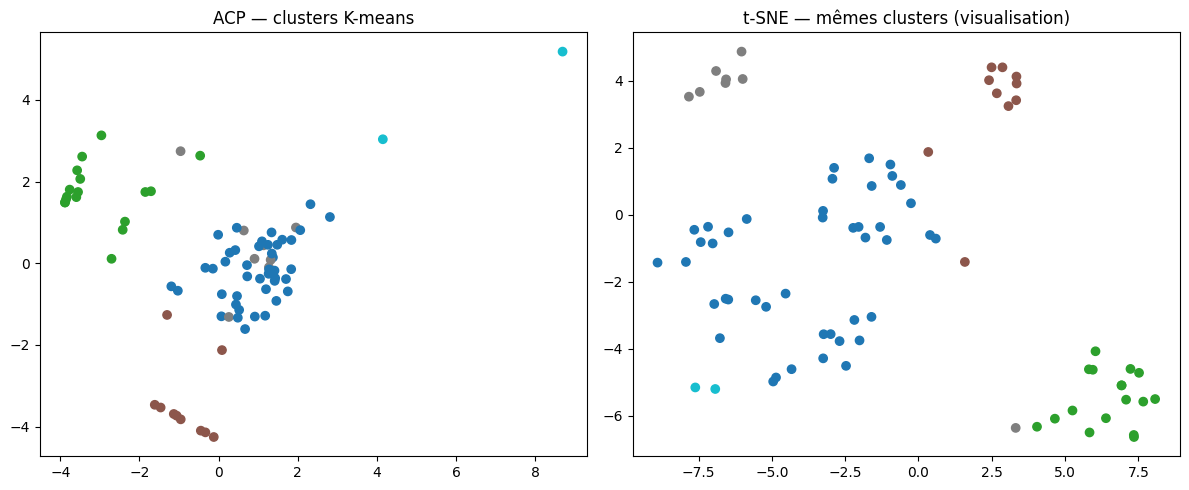

In [4]:
ks=range(2,min(7,len(profile)-1))
scores=[]
for k in ks:
 labels=KMeans(n_clusters=k,random_state=SEED,n_init=15).fit_predict(X)
 scores.append({'k':k,'silhouette':float(silhouette_score(X,labels))})
sel=pd.DataFrame(scores);k=int(sel.sort_values('silhouette',ascending=False).iloc[0].k)
profile['cluster_kmeans']=KMeans(n_clusters=k,random_state=SEED,n_init=20).fit_predict(X)
profile['cluster_agglomerative']=AgglomerativeClustering(n_clusters=k).fit_predict(X)
tSNE=TSNE(n_components=2,random_state=SEED,perplexity=min(20,max(5,(len(profile)-1)//4)),init='pca',learning_rate='auto').fit_transform(X)
profile['tsne_1']=tSNE[:,0];profile['tsne_2']=tSNE[:,1]
nei=NearestNeighbors(n_neighbors=5).fit(X)
d5=np.sort(nei.kneighbors(X)[0][:,-1]);eps=float(np.quantile(d5,.80))
profile['cluster_dbscan']=DBSCAN(eps=eps,min_samples=5).fit_predict(X)
display(sel.round(3));print('Meilleur k exploratoire :',k,'; DBSCAN points bruit :',int((profile.cluster_dbscan==-1).sum()))
fig,ax=plt.subplots(1,2,figsize=(12,5))
ax[0].scatter(profile.pca_1,profile.pca_2,c=profile.cluster_kmeans,cmap='tab10');ax[0].set_title('ACP — clusters K-means')
ax[1].scatter(profile.tsne_1,profile.tsne_2,c=profile.cluster_kmeans,cmap='tab10');ax[1].set_title('t-SNE — mêmes clusters (visualisation)')
plt.tight_layout();(ROOT/'figures').mkdir(exist_ok=True);plt.savefig(ROOT/'figures/cours2_projections_7.png',dpi=135);plt.show()


## 5. Regrouper les installations selon leur activité logistique

Pour les futurs croisements avec écologie et santé, il est aussi utile de caractériser **chaque site** (réception, départ/arrivée, commandes, corrections). Leurs coordonnées géographiques sont conservées dans l'export mais **exclues du clustering** pour éviter que des sites proches ne soient considérés identiques seulement par géographie.

In [5]:
sites=fc[['facility_code','facility_name','region','latitude','longitude','facility_category','operating_partner_code']].copy().set_index('facility_code')
for f,key,name in [(po,'ordering_facility_code','n_order_lines'),(rc,'receiving_facility_code','n_receipts'),(sh,'origin_facility_code','n_shipment_departures'),(sh,'destination_facility_code','n_shipment_arrivals'),(ad,'facility_code','n_adjustments'),(mo,'facility_code','n_month_end_rows')]:
 sites[name]=sites.index.map(f.groupby(key).size()).fillna(0).astype(int)
sites=sites.reset_index()
fcols=[col for col in sites if col.startswith('n_')]
Xs=StandardScaler().fit_transform(np.log1p(sites[fcols]))
ks2=range(2,min(6,len(sites)-1))
rank=[(q,silhouette_score(Xs,KMeans(n_clusters=q,n_init=15,random_state=SEED).fit_predict(Xs))) for q in ks2]
ksite=max(rank,key=lambda x:x[1])[0]
sites['cluster_activity']=KMeans(n_clusters=ksite,n_init=20,random_state=SEED).fit_predict(Xs)
p2=PCA(n_components=2).fit_transform(Xs);sites['pca_1']=p2[:,0];sites['pca_2']=p2[:,1]
profile.to_csv(OUT/'erp_partner_profiles_clustered.csv',index=False)
sites.to_csv(OUT/'erp_facility_profiles_clustered.csv',index=False)
print('Profils fournisseurs :',len(profile),' / sites :',len(sites))
display(profile.groupby('cluster_kmeans')[features].mean().round(1));display(sites.groupby('cluster_activity')[fcols].mean().round(1))


Profils fournisseurs : 80  / sites : 30


,n_orders,n_receipts,n_inspection_held,n_shipments_sent,n_shipments_received,n_shipments_carried,n_restricted_shipments,n_facilities_operated,n_facilities_served,n_order_categories,n_shipment_categories
cluster_kmeans,,,,,,,,,,,
0,8.7,8.1,0.6,4.9,5.7,0.0,0.5,0.4,6.2,6.7,4.3
1,0.4,0.4,0.0,4.6,5.1,0.0,0.6,0.2,0.4,0.4,4.2
2,8.1,7.7,0.1,0.2,0.6,0.0,0.0,0.0,5.6,5.8,0.2
3,6.2,5.6,0.2,4.4,4.6,51.0,0.6,0.8,5.0,5.5,4.1
4,69.0,67.0,3.5,62.5,38.0,21.0,11.0,2.0,5.5,15.5,13.5


,n_order_lines,n_receipts,n_shipment_departures,n_shipment_arrivals,n_adjustments,n_month_end_rows
cluster_activity,,,,,,
0,53.4,51.1,34.4,34.9,7.4,33.3
1,8.0,7.1,6.7,6.5,3.5,9.5


In [6]:
display(Markdown(f"""### Interprétation — Cours 2
- **{len(profile)} partenaires** et **{len(sites)} sites** représentés sous deux typologies distinctes.
- K-means partenaire : **{k} groupes** selon les nombres de commandes, réceptions et **expéditions**.
- K-means site : **{ksite} groupes** selon les flux entrants/sortants et les ajustements.
- Les profils et les projections contiennent leurs clés d'origine pour les rapprochements ultérieurs. Un groupe rare n'est pas une preuve de fraude."""))


### Interprétation — Cours 2
- **80 partenaires** et **30 sites** représentés sous deux typologies distinctes.
- K-means partenaire : **5 groupes** selon les nombres de commandes, réceptions et **expéditions**.
- K-means site : **2 groupes** selon les flux entrants/sortants et les ajustements.
- Les profils et les projections contiennent leurs clés d'origine pour les rapprochements ultérieurs. Un groupe rare n'est pas une preuve de fraude.